# NLA confabulation: a consistency filter, and what NLAs read

Natural language autoencoders (NLAs) turn a model's activation into a text explanation, but those
explanations often contain false claims. This notebook asks **which parts of an NLA readout can be
trusted using only the activation**, on [ceselder's open NLA](https://huggingface.co/ceselder/qwen3.6-27b-nla-rl)
for Qwen3.6-27B (layer 42, RL step 400), with [WorkspaceBench](https://www.lesswrong.com/posts/Zeg2JztbdhguL48uH/workspacebench-evaluating-interpretability-methods-for-the)
items as ground truth.

1. **Agreement filters confabulation.** Extending consensus sampling from activation oracles
   ([Bauer, 2026](https://arxiv.org/abs/2606.02609)) to NLA claims: agreement across 8 samples separates
   true from false claims about the input at AUROC 0.90, and right from wrong claims about internal
   computation at 0.75. Anthropic's adjacent-token heuristic ([NLA paper](https://transformer-circuits.pub/2026/nla/)),
   measured here for the first time, adds to it (0.80 combined).
2. **The NLA reads operands from the subspace the model uses, but imprecisely.** At "51 − 49 =", a linear probe
   reads both operands 83–93% of the time, but the NLA gets the first operand right 5% of the time (the
   "readout gap" of [Dingeto, 2026](https://arxiv.org/abs/2607.20379)). Swapping one operand's subspace in from
   another prompt shows why: the NLA follows 18 class-mean directions almost as well as the whole vector, but
   ignores the 18 directions the probe relies on, which move the probe and not the model's answer either.

Why NLAs confabulate (a reconstruction reward that pays for pseudo-quotes) is covered by
[Anurin](https://www.lesswrong.com/posts/4nZwNPyfoadAxPH98/natural-language-autoencoders-are-summarizers-but-do-they),
[Zhang & TurnTrout](https://www.lesswrong.com/posts/LQXWiF8PyJ5ojNsEv/how-robust-are-natural-language-autoencoders-to),
[Hong](https://www.lesswrong.com/posts/DFgt8fi3Wzwwe2Sib/fixing-rewards-for-nla-to-reduce-confabulation) and
[Lek et al.](https://arxiv.org/abs/2609.33702); it is not re-examined here.

![abstract](figures/nla_abstract.png)

## Data

Everything below is computed from the files in `data/` (no GPU or API calls needed):

| File | Contents |
| --- | --- |
| `claims/<family>.jsonl` | The original NLA readout of each of the 500 items split into atomic claims, each labelled against the source text by a Gemini judge (`workspace`, `background_true`, `misquote`, `contradicted`, `invented_content`, `unverifiable`) |
| `claims/<family>.readouts.jsonl` | The original NLA readouts |
| `claim_signals.jsonl` | Per claim: how many of 8 fresh NLA samples support it, how many of 3 readouts at the preceding tokens do (both judged by Gemini), and for claims about internal computation a correctness label (`correct` / `wrong` / `vague`, or `excluded` if ambiguous) |
| `nla_samples.jsonl` | The 8 samples and 3 adjacent-token readouts per item |
| `prior_consistency.jsonl` | Self-agreement of 8 samples on the mean vector, 20 random vectors and 40 real items |
| `arithmetic.jsonl` | 600 "a ± b =" prompts: operands, the model's next token, 5-fold linear-probe predictions of each digit, 2 NLA readouts |
| `steering.jsonl` | 300 few-shot prompt pairs differing in one operand: for each condition (original, whole source vector, class-mean / probe-weight / random subspace swap) the probe's reading, the model's answer and 8 NLA readouts |

The NLA only ever sees the activation vector, injected at a marker token of its own fixed prompt; it never sees the source text.

In [1]:
import json, re
from collections import Counter, defaultdict
from pathlib import Path
import matplotlib.pyplot as plt

D = Path("data")
FAMS = ["multihop", "poetry", "typo", "association", "basic_readout"]
BLUE, BLUE_LT, ORANGE, GREY, INK2 = "#2a78d6", "#8db8ec", "#eb6834", "#8a8984", "#52514e"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#b9b8b3", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2})

def jl(p):
    return [json.loads(l) for l in open(p) if l.strip()]

def auroc(pos, neg):
    """P(score of a positive > score of a negative), ties count half."""
    return sum((p > n) + 0.5 * (p == n) for p in pos for n in neg) / (len(pos) * len(neg))

claims = {(f, r["id"]): r["claims"] for f in FAMS for r in jl(D / "claims" / f"{f}.jsonl")}
sig = {d["key"]: d for d in jl(D / "claim_signals.jsonl")}
recs = []
for (f, i), cl in claims.items():
    for n, c in enumerate(cl):
        s = sig.get(f"{f}|{i}|{n}", {})
        recs.append({"family": f, "id": i, "claim": c["claim"], "label": c["label"],
                     "samples": s.get("sample_support_of_8"), "adjacent": s.get("adjacent_support_of_3"),
                     "internal": s.get("internal_label")})
print(len(claims), "items,", len(recs), "claims")
print(dict(Counter(r["label"] for r in recs)))

500 items, 4190 claims
{'contradicted': 514, 'misquote': 1081, 'background_true': 854, 'workspace': 1281, 'invented_content': 171, 'unverifiable': 289}


## Result 1a: agreement across samples filters false claims about the input

For each claim of the original readout, count how many of 8 fresh samples of the same activation
state it. "True" = `workspace` or `background_true`; "false" = `misquote` or `contradicted`.

In [2]:
TRUE, FALSE = ("workspace", "background_true"), ("misquote", "contradicted")
inp = [r for r in recs if r["samples"] is not None]
t = [r["samples"] for r in inp if r["label"] in TRUE]
fl = [r["samples"] for r in inp if r["label"] in FALSE]
print(f"AUROC, samples:  {auroc(t, fl):.2f}   (n = {len(t)} true, {len(fl)} false)")
both = [r for r in inp if r["adjacent"] is not None]
print(f"AUROC, adjacent: {auroc([r['adjacent'] for r in both if r['label'] in TRUE], [r['adjacent'] for r in both if r['label'] in FALSE]):.2f}")
print(f"AUROC, both:     {auroc([r['samples']/8 + r['adjacent']/3 for r in both if r['label'] in TRUE], [r['samples']/8 + r['adjacent']/3 for r in both if r['label'] in FALSE]):.2f}")

print("\nmean support (of 8) by label:")
for lab in ["workspace", "background_true", "unverifiable", "invented_content", "contradicted", "misquote"]:
    v = [r["samples"] for r in inp if r["label"] == lab]
    print(f"  {lab:17s} {sum(v)/len(v):.2f}  (n={len(v)})")

AUROC, samples:  0.90   (n = 2135 true, 1594 false)
AUROC, adjacent: 0.74


AUROC, both:     0.92

mean support (of 8) by label:
  workspace         6.24  (n=1281)
  background_true   6.57  (n=854)
  unverifiable      4.48  (n=288)
  invented_content  2.35  (n=170)
  contradicted      1.59  (n=513)
  misquote          0.77  (n=1081)


In [3]:
tot = Counter(r["label"] for r in inp)
nfalse = sum(tot[l] for l in FALSE)
items = {(r["family"], r["id"]) for r in inp}
print(f"{'filter':28s} {'kept':>5s} {'false among kept':>17s} {'workspace kept':>15s} {'true bg kept':>13s} {'readouts w/ false':>18s}")
for name, m in [("none", 0), ("support >= 1 of 8", 1), ("support >= 2 of 8", 2), ("support >= 4 of 8", 4)]:
    kept = [r for r in inp if r["samples"] >= m]
    c = Counter(r["label"] for r in kept)
    bad = {(r["family"], r["id"]) for r in kept if r["label"] in FALSE}
    print(f"{name:28s} {len(kept):5d} {100*sum(c[l] for l in FALSE)/len(kept):16.0f}% {100*c['workspace']/tot['workspace']:14.0f}% "
          f"{100*c['background_true']/tot['background_true']:12.0f}% {100*len(bad)/len(items):17.0f}%")

filter                        kept  false among kept  workspace kept  true bg kept  readouts w/ false
none                          4187               38%            100%          100%                99%
support >= 1 of 8             2706               16%             91%           95%                58%
support >= 2 of 8             2493               13%             87%           93%                46%
support >= 4 of 8             2212                9%             81%           86%                33%


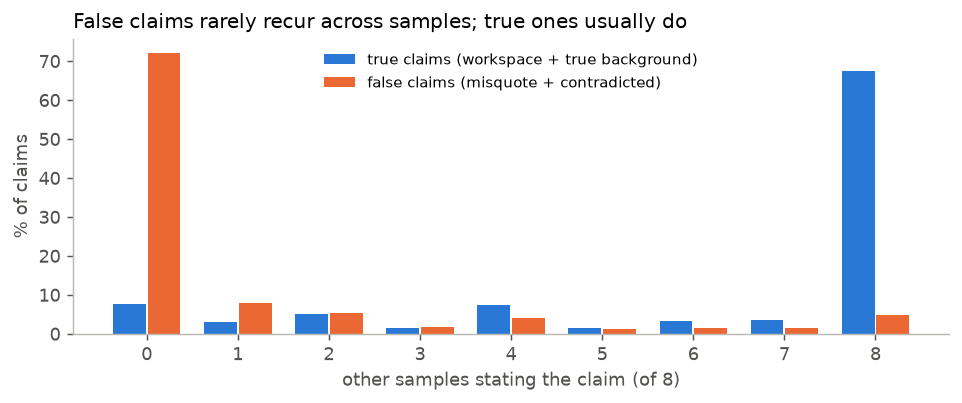

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.2))
xs = range(9)
for k, (labs, name, col) in enumerate([(TRUE, "true claims (workspace + true background)", BLUE), (FALSE, "false claims (misquote + contradicted)", ORANGE)]):
    v = Counter(r["samples"] for r in inp if r["label"] in labs)
    n = sum(v.values())
    ax.bar([x + (k - 0.5) * 0.38 for x in xs], [100 * v[x] / n for x in xs], width=0.36, color=col, label=name)
ax.set_xticks(list(xs)); ax.set_xlabel("other samples stating the claim (of 8)"); ax.set_ylabel("% of claims")
ax.set_title("False claims rarely recur across samples; true ones usually do", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8.5); fig.tight_layout(); fig.savefig("figures/input_support.png", dpi=200)

## Result 1b: claims about internal computation

Claims the judge labelled `workspace` (what the model is computing or about to write) were graded against
the WorkspaceBench target and the true final answer. Every claim graded wrong was checked by hand, and
ambiguous ones (continuations whose truth is unknown) were excluded.

Anthropic's adjacent-token heuristic: trust a claim more if the NLA also makes it when reading the
activations at the few tokens just before. Here: one readout at each of the 3 preceding tokens.

In [5]:
ws = [r for r in recs if r["internal"] in ("correct", "wrong") and r["samples"] is not None and r["adjacent"] is not None]
c = [r for r in ws if r["internal"] == "correct"]; w = [r for r in ws if r["internal"] == "wrong"]
print(f"{len(c)} correct, {len(w)} wrong internal claims")
signals = {"8 samples": lambda r: r["samples"], "3 preceding tokens": lambda r: r["adjacent"],
           "both (samples/8 + tokens/3)": lambda r: r["samples"] / 8 + r["adjacent"] / 3}
for name, g in signals.items():
    print(f"AUROC {name:28s} {auroc([g(r) for r in c], [g(r) for r in w]):.2f}")
cc = [r["adjacent"] for r in c if r["samples"] >= 7]; wc = [r["adjacent"] for r in w if r["samples"] >= 7]
print(f"AUROC preceding tokens, among claims >= 7 of 8 samples agree on: {auroc(cc, wc):.2f}  ({len(cc)} correct, {len(wc)} wrong)")
print("\nper family (samples):")
for f in FAMS:
    cf = [r["samples"] for r in c if r["family"] == f]; wf = [r["samples"] for r in w if r["family"] == f]
    if cf and wf:
        print(f"  {f:14s} AUROC {auroc(cf, wf):.2f}  ({len(cf)} correct, {len(wf)} wrong)")

600 correct, 121 wrong internal claims
AUROC 8 samples                    0.75
AUROC 3 preceding tokens           0.69
AUROC both (samples/8 + tokens/3)  0.80
AUROC preceding tokens, among claims >= 7 of 8 samples agree on: 0.67  (443 correct, 39 wrong)

per family (samples):
  multihop       AUROC 0.82  (177 correct, 14 wrong)
  poetry         AUROC 0.68  (35 correct, 54 wrong)
  typo           AUROC 0.81  (166 correct, 1 wrong)
  association    AUROC 0.95  (99 correct, 1 wrong)
  basic_readout  AUROC 0.72  (123 correct, 51 wrong)


In [6]:
print(f"{'filter on internal claims':38s} {'wrong among kept':>17s} {'correct kept':>13s} {'wrong removed':>14s}")
for name, keep in [("none", lambda r: True), ("samples >= 4 of 8", lambda r: r["samples"] >= 4),
                   ("preceding tokens >= 1 of 3", lambda r: r["adjacent"] >= 1),
                   ("both", lambda r: r["samples"] >= 4 and r["adjacent"] >= 1)]:
    kept = [r for r in ws if keep(r)]
    kw = sum(r["internal"] == "wrong" for r in kept)
    print(f"{name:38s} {100*kw/len(kept):16.0f}% {100*(len(kept)-kw)/len(c):12.0f}% {100*(1-kw/len(w)):13.0f}%")

filter on internal claims               wrong among kept  correct kept  wrong removed
none                                                 17%          100%             0%
samples >= 4 of 8                                    10%           84%            53%
preceding tokens >= 1 of 3                            6%           52%            83%
both                                                  5%           46%            88%


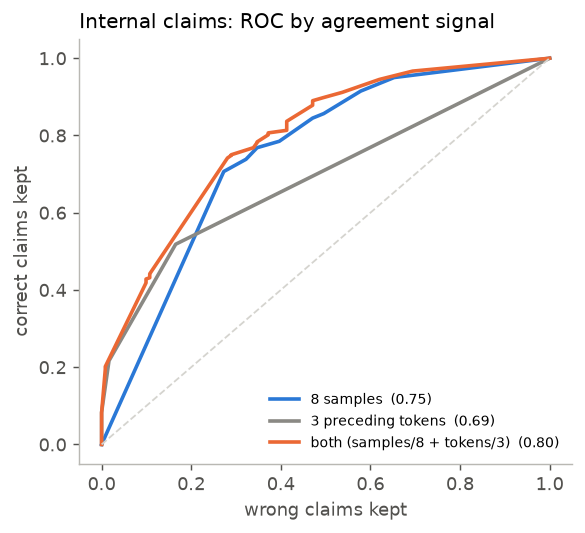

In [7]:
def roc(pos, neg):
    ts = sorted(set(pos + neg), reverse=True)
    pts = [(0.0, 0.0)] + [(sum(n >= t for n in neg) / len(neg), sum(p >= t for p in pos) / len(pos)) for t in ts]
    return [x for x, _ in pts], [y for _, y in pts]

fig, ax = plt.subplots(figsize=(4.6, 4.2))
for (name, g), col in zip(signals.items(), [BLUE, GREY, ORANGE]):
    x, y = roc([g(r) for r in c], [g(r) for r in w])
    ax.plot(x, y, color=col, lw=2, label=f"{name}  ({auroc([g(r) for r in c], [g(r) for r in w]):.2f})")
ax.plot([0, 1], [0, 1], color="#d5d4cf", lw=1, ls="--")
ax.set_xlabel("wrong claims kept"); ax.set_ylabel("correct claims kept")
ax.set_title("Internal claims: ROC by agreement signal", loc="left", fontsize=11)
ax.legend(frameon=False, fontsize=8, loc="lower right"); fig.tight_layout(); fig.savefig("figures/internal_roc.png", dpi=200)

Wrong internal claims split into errors that vary across samples (which sampling catches) and errors the
NLA repeats in at least 7 of 8 samples. Many of the repeated ones come from the NLA rebuilding a
consistent wrong copy of the task, then answering that copy:

In [8]:
rep = [r for r in w if r["samples"] >= 7]
print(f"{len(rep)} of {len(w)} wrong internal claims repeat in >= 7 of 8 samples; "
      f"{sum(r['adjacent'] == 0 for r in rep)} of those appear at none of the preceding tokens\n")
for r in rep[:10]:
    print(f"[{r['family']}/{r['id']}] samples {r['samples']}/8, preceding {r['adjacent']}/3: {r['claim'][:110]}")

39 of 121 wrong internal claims repeat in >= 7 of 8 samples; 27 of those appear at none of the preceding tokens

[multihop/double-dice-faces] samples 8/8, preceding 1/3: The final fragment requires completion with a mathematical expression, number, or clause like 'equal to...' or
[multihop/holiday-valentines-monthnum] samples 8/8, preceding 0/3: The model expects a number or descriptive phrase like '7' as the immediate next token.
[multihop/nhop-cube-element] samples 8/8, preceding 0/3: The next token demands an immediate specific element name such as Oxygen or Argon.
[multihop/nhop-cube-element] samples 7/8, preceding 0/3: The structure requires the name of an element at atomic number 8 or another numbered element like silicon.
[multihop/rhyme-tree-squared] samples 8/8, preceding 0/3: The next token is almost certainly a number or word describing the square value (e.g., 'three').
[poetry/couplet-smoke-spoke] samples 8/8, preceding 1/3: The next token must begin the second line of the 

### How consistent is the NLA with nothing to read?

For each vector, sample 1's claims are counted against the other 7 samples. On random vectors at the
activation norm, a substantial share of claims are still self-consistent: consistency is evidence, not proof.

In [9]:
pr = {d["key"]: d["r"]["claims"] for d in jl(D / "prior_consistency.jsonl")}
for kind, name in [("real", "real activations"), ("noise", "random vectors"), ("mean", "mean activation")]:
    v = [x["support"] for k, cl in pr.items() if k.startswith(kind) for x in cl]
    print(f"{name:17s} mean support {sum(v)/len(v):.2f} of 7, claims at >= 6 of 7: {100*sum(x >= 6 for x in v)/len(v):3.0f}%  (n={len(v)} claims)")

real activations  mean support 6.22 of 7, claims at >= 6 of 7:  84%  (n=243 claims)
random vectors    mean support 3.36 of 7, claims at >= 6 of 7:  29%  (n=146 claims)
mean activation   mean support 5.29 of 7, claims at >= 6 of 7:  71%  (n=7 claims)


## Result 2: the NLA reads operands from the subspace the model uses, but imprecisely

600 prompts "a ± b =" (a, b ≤ 99) in WorkspaceBench's plain format, read at the final token. Probes are
5-fold logistic regressions predicting each digit of a and b from the layer-42 activation; the NLA was
sampled twice per prompt and the first "x ± y" expression in its readout parsed. In this format Qwen's next
token is " ?", not the answer (answer digits decode at only 38–45%), so this tests reading the operands,
not the computed result. The probe is supervised on this format and the NLA is not: the claim is that the
operands are linearly present, not that the NLA could easily read them.

In [10]:
ar = jl(D / "arithmetic.jsonl")
expr = re.compile(r"(\d+)\s*([-\u2212+])\s*(\d+)")
rows = []
for r in ar:
    pa = r["probe_a_tens"] == r["a"] // 10 and r["probe_a_units"] == r["a"] % 10
    pb = r["probe_b_tens"] == r["b"] // 10 and r["probe_b_units"] == r["b"] % 10
    for t in r["nla_readouts"]:
        m = expr.search(t)
        rows.append({"a": r["a"], "b": r["b"], "op": r["op"], "probe_a": pa, "probe_b": pb,
                     "nla_a": int(m.group(1)) if m else None, "nla_op": m.group(2) if m else None,
                     "nla_b": int(m.group(3)) if m else None, "text": t})
q = [x for x in rows if x["nla_a"] is not None]
print(f"NLA readouts quoting an expression: {100*len(q)/len(rows):.0f}% of {len(rows)}")
print(f"{'':10s} {'probe exact':>12s} {'NLA exact':>10s}")
print(f"{'a':10s} {100*sum(x['probe_a'] for x in rows)/len(rows):11.0f}% {100*sum(x['nla_a']==x['a'] for x in q)/len(q):9.0f}%")
print(f"{'b':10s} {100*sum(x['probe_b'] for x in rows)/len(rows):11.0f}% {100*sum(x['nla_b']==x['b'] for x in q)/len(q):9.0f}%")
print(f"{'operator':10s} {'100':>11s}% {100*sum((x['nla_op']=='+')==(x['op']=='+') for x in q)/len(q):9.0f}%")
wrong = [x for x in q if (x["nla_a"], x["nla_b"]) != (x["a"], x["b"])]
print(f"\nwrong NLA expressions where the probe decodes both operands: {100*sum(x['probe_a'] and x['probe_b'] for x in wrong)/len(wrong):.0f}%")
for x in wrong[:6]:
    print(f"  {x['a']} {x['op']} {x['b']}  ->  NLA: {expr.search(x['text']).group(0)}")

NLA readouts quoting an expression: 100% of 1200
            probe exact  NLA exact
a                   83%         5%
b                   93%        38%
operator           100%       100%

wrong NLA expressions where the probe decodes both operands: 79%
  51 - 49  ->  NLA: 64 - 49
  51 - 49  ->  NLA: 58 - 46
  55 + 6  ->  NLA: 13 + 6
  55 + 6  ->  NLA: 12 + 6
  35 - 33  ->  NLA: 36 - 23
  35 - 33  ->  NLA: 37 - 23


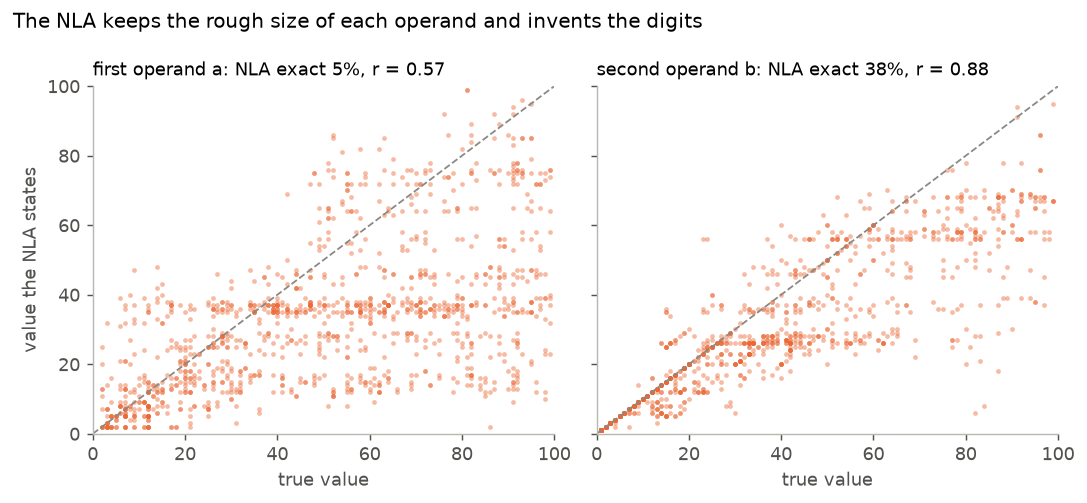

In [11]:
def corr(u, v):
    mu, mv = sum(u) / len(u), sum(v) / len(v)
    return sum((a - mu) * (b - mv) for a, b in zip(u, v)) / (sum((a - mu) ** 2 for a in u) * sum((b - mv) ** 2 for b in v)) ** 0.5

fig, axs = plt.subplots(1, 2, figsize=(8.4, 3.9), sharex=True, sharey=True)
for ax, key, name in [(axs[0], "a", "first operand a"), (axs[1], "b", "second operand b")]:
    tv = [x[key] for x in q]; nv = [x["nla_" + key] for x in q]
    ax.scatter(tv, nv, s=7, color=ORANGE, alpha=0.45, lw=0)
    ax.plot([0, 100], [0, 100], color=GREY, lw=1, ls="--")
    exact = 100 * sum(a == b for a, b in zip(tv, nv)) / len(tv)
    ax.set_title(f"{name}: NLA exact {exact:.0f}%, r = {corr(tv, nv):.2f}", loc="left", fontsize=10)
    ax.set_xlabel("true value"); ax.set_xlim(0, 100); ax.set_ylim(0, 100)
axs[0].set_ylabel("value the NLA states")
fig.suptitle("The NLA keeps the rough size of each operand and invents the digits", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); fig.savefig("figures/operand_scatter.png", dpi=200)

### Which directions does the NLA read?

A probe reading a value does not show that the model uses the directions it reads. In a few-shot format (four
solved lines, then "a ± b =") Qwen answers correctly, so we built 300 held-out prompt pairs that differ in one
operand: the first operand (two digits), the second (two digits), and the second with one digit, which the NLA
reads well (the positive control). In each pair one operand's subspace at "=" is copied from the source prompt
into the original, h' = h + UUᵀ(h_src − h), with 18 directions from the class means of that operand's digits,
18 from the logistic probe's weights, or 18 random ones. The NLA is sampled 8 times per condition and the
incomplete equation it quotes ("96 − 34 =") parsed; completed lines it invents ("54 + 43 = 97") are ignored.

Measures: *closer* = share of NLA readouts whose number is nearer the swapped-in value than the original;
*exact* = share naming the swapped-in value; *probe* = share of prompts where the probe reads it; *model* = share
where the model's answer becomes the source prompt's answer (patching only at "=").

In [12]:
FEW = {(12, "+", 7), (45, "-", 13), (8, "+", 26), (71, "-", 9)}
OPEN = re.compile(r"(?<![\d.])(\d+)[ \t]*([-−+])[ \t]*(\d+)[ \t]*=(?![ \t]*\d)")

def target(t):
    hits = [(int(x), "-" if o == "−" else o, int(y)) for x, o, y in OPEN.findall(t)]
    hits = [h for h in hits if h not in FEW]
    return max(hits, key=lambda h: (hits.count(h), -hits.index(h))) if hits else None

def answer(s):
    t = s.strip().split()[0] if s.strip() else ""
    return int(t) if t.lstrip("-").isdigit() else None

st = jl(D / "steering.jsonl")
print(f"model right on original prompts: {sum(answer(r['model']['base']) == (r['base'][0] - r['base'][1] if r['op'] == '-' else sum(r['base'])) for r in st)}/{len(st)}; "
      f"patching a vector back into its own prompt leaves the answer unchanged: {sum(r['model']['self'] == r['model']['base'] for r in st)}/{len(st)}")
CONDS = [("base", "original"), ("src", "whole source vector"), ("swap_mean", "class-mean subspace"),
         ("swap_lr", "probe-weight subspace"), ("swap_rand", "random subspace")]
for var, name, i in [("b1", "second operand, one digit", 1), ("a", "first operand, two digits", 0), ("b", "second operand, two digits", 1)]:
    rs = [r for r in st if r["var"] == var]
    print(f"\n{name} ({len(rs)} pairs)\n{'':24s} {'closer':>7s} {'exact':>6s} {'probe':>6s} {'model':>6s}")
    for c, lab in CONDS:
        near = far = ex = n = 0
        for r in rs:
            for t in r["nla_readouts"][c]:
                p = target(t)
                if p:
                    v = p[0] if i == 0 else p[2]
                    n += 1; ex += v == r["src"][i]
                    ds, db = abs(v - r["src"][i]), abs(v - r["base"][i])
                    near += ds < db; far += db < ds
        probe = "" if c == "base" else f"{sum(r['probe'][c][i] == r['src'][i] for r in rs) / len(rs):6.0%}"
        mc = "full" if c == "src" else c
        src_ans = lambda r: r["src"][0] - r["src"][1] if r["op"] == "-" else sum(r["src"])
        model = "" if c == "base" else f"{sum(answer(r['model'][mc]) == src_ans(r) for r in rs) / len(rs):6.0%}"
        print(f"{lab:24s} {near / max(near + far, 1):7.0%} {ex / max(n, 1):6.0%} {probe:>6s} {model:>6s}")

model right on original prompts: 300/300; patching a vector back into its own prompt leaves the answer unchanged: 300/300

second operand, one digit (100 pairs)
                          closer  exact  probe  model
original                     10%     1%              
whole source vector          88%    77%    97%    42%
class-mean subspace          88%    74%    85%    28%
probe-weight subspace        10%     1%    97%     0%
random subspace               9%     1%     0%     0%

first operand, two digits (100 pairs)
                          closer  exact  probe  model
original                     14%     0%              


whole source vector          87%    19%    92%     0%


class-mean subspace          76%     7%    54%     0%
probe-weight subspace        26%     2%    92%     0%
random subspace              16%     0%     0%     0%

second operand, two digits (100 pairs)
                          closer  exact  probe  model
original                     33%     1%              
whole source vector          70%     9%    89%     0%
class-mean subspace          60%     5%    40%     0%
probe-weight subspace        38%     2%    89%     0%
random subspace              35%     1%     0%     0%


![steering](figures/steer.png)

(Drawn by `scripts/steer_figure.py` from the same data.) The NLA follows the class-mean swap almost as well as
the whole vector and ignores the probe-weight swap, which moves the probe 89–97% of the time but leaves the NLA at
the random level. The model behaves like the NLA where this can be seen: patching only at "=" never changes a
two-digit answer (later layers read the operand tokens directly), but on one-digit operands class-mean swaps change
the answer 28% of the time and probe-weight swaps never do. So part of the probe's lead over the NLA comes from
directions neither the model at this position nor the NLA uses; on the directions that matter, the NLA tracks the
operand but imprecisely.

## Limitations

- One open NLA (ceselder's replication on Qwen3.6-27B, layer 42, step 400), not Anthropic's NLAs.
- Claim labels come from one Gemini judge; every wrong internal claim was checked by hand.
- The preceding tokens hold different content from the read token, so the adjacent-token check also drops many correct claims.
- Result 2 covers one probe target (operands, not computed results). "The model uses these directions" rests on one-digit operands, since patching at "=" alone cannot change a two-digit answer; on two-digit operands the class-mean swap moves the probe only 40–54% of the time.

## Reproducing the data

The `scripts/` folder holds the pipeline that produced `data/` (needs a GPU with ~140 GB for the model and NLA together, the
[workspace-bench](https://github.com/camilablank/workspace-bench) package, and an OpenRouter key for the judges):

| Step | Script |
| --- | --- |
| NLA samples, adjacent-token readouts, control vectors, arithmetic activations and probes (GPU) | `nla_verify_pod.py`, `thread12_pod.py` (batched NLA reader in `deception_pod.py`) |
| Claim decomposition and labels against the source | `claim_judge.py` |
| Sample and adjacent-token support, prior consistency | `nla_verify_eval.py`, `t12_eval.py` |
| Correctness of internal claims | `ws_correct.py` (then a hand check) |
| Steering test: activations, probes, subspace swaps, model answers, NLA readouts (GPU) | `steer_pod.py`; report and figure: `steer_eval.py`, `steer_figure.py` |
| Abstract figure | `abstract_figure.py` |